# Hierarchical clustering of persistence diagrams across cities

This notebook compares the **shape of accessibility** across cities. Its unit of
observation is a city, but each city is represented by four persistence diagrams:

| key | filtration | homology | interpretation |
|---|---|---:|---|
| `sub_h0` | sublevel | $H_0$ | connected components of areas reachable within $t$ minutes |
| `sub_h1` | sublevel | $H_1$ | enclosed inaccessible holes within the reached area |
| `sup_h0` | superlevel | $H_0$ | connected components of high-travel-time cells |
| `sup_h1` | superlevel | $H_1$ | loops in the high-travel-time region |

The pipeline is:

$$
\text{CSV diagrams}\longrightarrow
\text{lifetime filter}\longrightarrow
\text{four city-distance matrices}\longrightarrow
\text{median scaling + mean}\longrightarrow
\text{hierarchical trees}.
$$

## Where the persistence diagrams come from

This notebook **does not recompute persistent homology**. It reads the CSV files
created upstream by `level_set_both.ipynb`. In that notebook:

1. A tessellation cell is a vertex $v$ and carries a travel-time value $f(v)$ in minutes
   (values are clipped at 60 minutes).
2. Spatially adjacent cells create graph edges. Filling all graph cliques through
   dimension 2 gives a filtered clique complex $K$; the 2-skeleton is sufficient for
   computing $H_0$ and $H_1$.
3. In the sublevel filtration, a simplex $\sigma$ enters at

   $$F_{\mathrm{sub}}(\sigma)=\max_{v\in\sigma}f(v).$$

   Thus every vertex of $\sigma$ is present by the time the simplex is inserted.
4. The superlevel filtration is implemented as a sublevel filtration of $g=-f$:

   $$F_g(\sigma)=\max_{v\in\sigma}g(v)=-\min_{v\in\sigma}f(v).$$

5. GUDHI's `SimplexTree.compute_persistence` computes $H_0$ and $H_1$ over the
   field $\mathbb F_2$. The resulting intervals are saved as `(birth_min, death_min)`.
   Sublevel intervals normally have $b<d$; after converting the negated superlevel
   values back to minutes, superlevel intervals have $b>d$.

So a persistence-diagram point is $p_i=(b_i,d_i)$. Its lifetime is always taken as

$$\ell_i=|d_i-b_i|,$$

which works for both interval orientations. $H_0$ tracks connected components and
$H_1$ tracks one-dimensional holes. An infinite endpoint denotes an **essential**
class that never dies within the finite filtration.

## Outputs made here

The plotting library is **Matplotlib**. SciPy creates the linkage matrices and draws
the dendrogram geometry; POT solves the normalized optimal-transport problem; GUDHI
is only imported if classical diagram Wasserstein distance is selected. This notebook
writes filtered-diagram scatterplots, a threshold-sensitivity plot, five dendrograms,
a silhouette panel, a combined-distance heatmap, and CSV tables/matrices.

> **Terminology note.** `normalized_ot` normalizes each city's *total mass*, making it
> insensitive to raw feature count. It is not dimensionless: point coordinates and
> the resulting distances are still measured in minutes. Only the later combined
> distance is made unitless by dividing each matrix by its median.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import ot  # POT: pip install pot
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform

# ---------------- parameters ----------------
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, cwd / "pedestrian_accessibility", *cwd.parents)
    if (path / "data/input/shape").is_dir()
)
RAW_DIR = (repo_root / "level_sets_blocks/results/experiment_1_complete_cities"
           / "persitent_parks_raw")
OUT_DIR = RAW_DIR.parent / "pd_clustering_parks"

TAU = 2                 # keep features with lifetime >= TAU minutes
DROP_ESSENTIAL = True      # drop classes with infinite death
DISTANCE = "normalized_ot" # "normalized_ot" | "classical_w1"
WEIGHT = "uniform"        # normalized_ot only: "lifetime" | "uniform"
LINKAGE = "average"        # "average" | "complete" | "single"  (Ward needs Euclidean distances)
K_RANGE = range(2, 7)      # numbers of clusters to evaluate
# --------------------------------------------

DIAGRAMS = {
    "sub_h0": ("sublevel", 0, "Sublevel H0"),
    "sub_h1": ("sublevel", 1, "Sublevel H1"),
    "sup_h0": ("superlevel", 0, "Superlevel H0"),
    "sup_h1": ("superlevel", 1, "Superlevel H1"),
}
OUT_DIR.mkdir(exist_ok=True)
print("output folder:", OUT_DIR)

output folder: level_sets_blocks/results/experiment_1_complete_cities/pd_clustering_parks


## 1. Configuration and data loading

`DIAGRAMS` is the single mapping between the short keys used below, the CSV filename
stem, the homology dimension, and the human-readable plot label. A city is included
only if **all four** required CSVs exist, keeping every distance matrix comparable.

For city $c$ and diagram type $r$, `PD_RAW[(c, r)]` is an $m_{cr}\times2$ array

$$D_c^{(r)}=\{(b_i,d_i)\}_{i=1}^{m_{cr}}.$$

The rows are topological features, not geographical coordinates; both columns are
times in minutes.

In [15]:
def read_pd(city_dir, filt, dim):
    """Load one persistence diagram as an (n_features, 2) float array."""
    df = pd.read_csv(city_dir / f"{filt}_h{dim}_persistence.csv")
    return df[["birth_min", "death_min"]].to_numpy(dtype=float)  # 'inf' parses as np.inf

# Complete-case selection: every retained city must have all four diagrams.
cities = sorted(
    d.name for d in RAW_DIR.iterdir()
    if d.is_dir() and all((d / f"{f}_h{k}_persistence.csv").exists() for f, k, _ in DIAGRAMS.values())
)
skipped = sorted(d.name for d in RAW_DIR.iterdir() if d.is_dir() and d.name not in cities)

# Dictionary key = (city name, diagram key); value = rows (birth, death).
PD_RAW = {(c, key): read_pd(RAW_DIR / c, f, k) for c in cities for key, (f, k, _) in DIAGRAMS.items()}

print(f"{len(cities)} cities:", ", ".join(cities))
if skipped:
    print("skipped (missing one of the four CSVs):", ", ".join(skipped))

17 cities: barranquilla, bogota, bucaramanga, cali, cartagena, cucuta, ibague, manizales, medellin, monteria, neiva, pasto, pereira, popayan, santa_marta, valledupar, villavicencio


## 2. Remove short-lived and essential features

For every point $p_i=(b_i,d_i)$, define persistence/lifetime

$$\ell_i=|d_i-b_i|.$$

With `TAU = 2`, the retained finite diagram is

$$D_{c,\tau}^{(r)}=\{(b_i,d_i)\in D_c^{(r)}:\ell_i\ge\tau\}.$$

Short lifetimes lie close to the diagonal $b=d$ and are commonly treated as small-scale
topological variation. `DROP_ESSENTIAL=True` first removes any row containing $\pm\infty$;
therefore the `~isfinite(life)` part of `keep` matters only when essential points are
explicitly retained. The assertion stops the pipeline if filtering empties a diagram,
because the normalized probability measure below would then be undefined.

The summary table reports counts and

$$\operatorname{pct\_kept}=100\,\frac{\#D_{c,\tau}^{(r)}}{\#D_c^{(r)}}.
$$

In [16]:
def filter_pd(d, tau=TAU, drop_essential=DROP_ESSENTIAL):
    """Keep points whose absolute birth/death separation is at least tau."""
    # A point is finite only when both birth and death are finite.
    finite = np.isfinite(d).all(axis=1)
    if drop_essential:
        d = d[finite]
    # Absolute value handles sublevel (death > birth) and superlevel (birth > death).
    life = np.abs(d[:, 1] - d[:, 0])
    keep = (life >= tau) | ~np.isfinite(life)
    return d[keep]

PD = {k: filter_pd(v) for k, v in PD_RAW.items()}

# One row per city × diagram type, used to audit how aggressive TAU is.
summary = pd.DataFrame(
    [{"city": c, "diagram": key,
      "n_raw": len(PD_RAW[(c, key)]),
      "n_essential": int((~np.isfinite(PD_RAW[(c, key)]).all(1)).sum()),
      "n_kept": len(PD[(c, key)]),
      "max_lifetime": np.abs(np.diff(PD[(c, key)], axis=1)).max() if len(PD[(c, key)]) else 0.0}
     for c in cities for key in DIAGRAMS]
)
summary["pct_kept"] = 100 * summary.n_kept / summary.n_raw
summary.to_csv(OUT_DIR / f"filter_summary_tau{TAU:g}.csv", index=False)

empty = summary[summary.n_kept == 0]
assert empty.empty, f"empty diagrams after filtering, lower TAU:\n{empty}"
summary.pivot(index="city", columns="diagram", values="n_kept").join(
    summary.groupby("city").pct_kept.mean().rename("mean_pct_kept").round(1))

,sub_h0,sub_h1,sup_h0,sup_h1,mean_pct_kept
city,,,,,
barranquilla,121,52,112,101,11.9
bogota,699,425,548,649,18.9
bucaramanga,149,103,173,110,23.0
cali,164,94,140,142,17.1
cartagena,108,51,81,91,16.3
cucuta,119,78,132,106,18.8
ibague,102,39,88,80,20.1
manizales,67,33,71,51,22.7
medellin,377,195,357,293,23.3


### Figure 1 — sensitivity to the lifetime threshold

For each city $c$, diagram type $r$, and candidate threshold $t$, the plotted fraction is

$$q_{cr}(t)=\frac{1}{N_{cr}}\sum_{i=1}^{N_{cr}}\mathbf1\{\ell_i\ge t\},$$

using finite features only. The solid curve is $\operatorname{median}_c q_{cr}(t)$;
the shaded band runs from the minimum to maximum city value. The dashed vertical line
marks the chosen `TAU`. `np.linspace` makes the threshold grid, `ax.plot` draws the
median, and `ax.fill_between` draws the range.

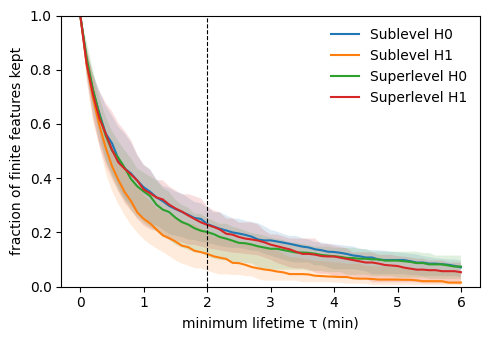

In [17]:
# How many features survive as a function of the threshold (median and range across cities)
taus = np.linspace(0, 6, 61)
fig, ax = plt.subplots(figsize=(5, 3.5))
for key, (_, _, label) in DIAGRAMS.items():
    frac = np.array([[ (np.abs(np.diff(PD_RAW[(c, key)][np.isfinite(PD_RAW[(c, key)]).all(1)], axis=1)) >= t).mean()
                      for t in taus] for c in cities])
    ax.plot(taus, np.median(frac, 0), label=label)
    ax.fill_between(taus, frac.min(0), frac.max(0), alpha=0.15)
ax.axvline(TAU, color="k", ls="--", lw=0.8)
ax.set_xlabel("minimum lifetime τ (min)"); ax.set_ylabel("fraction of finite features kept")
ax.legend(frameon=False); ax.set_ylim(0, 1)
fig.tight_layout(); fig.savefig(OUT_DIR / "fraction_kept_vs_tau.png", dpi=200)

### Figure 2 — the filtered persistence diagrams

`ax.scatter` plots every retained feature at $(b_i,d_i)$, coloured by city. The black
line is the diagonal $b=d$, where lifetime is zero; perpendicular distance to it is
$\ell_i/\sqrt2$. Sublevel points generally lie above it ($b<d$), while the converted
superlevel points generally lie below it ($b>d$). Equal axis limits and
`set_aspect("equal")` prevent visual distortion. This plot overlays cities; it does not
participate in the distance calculation.

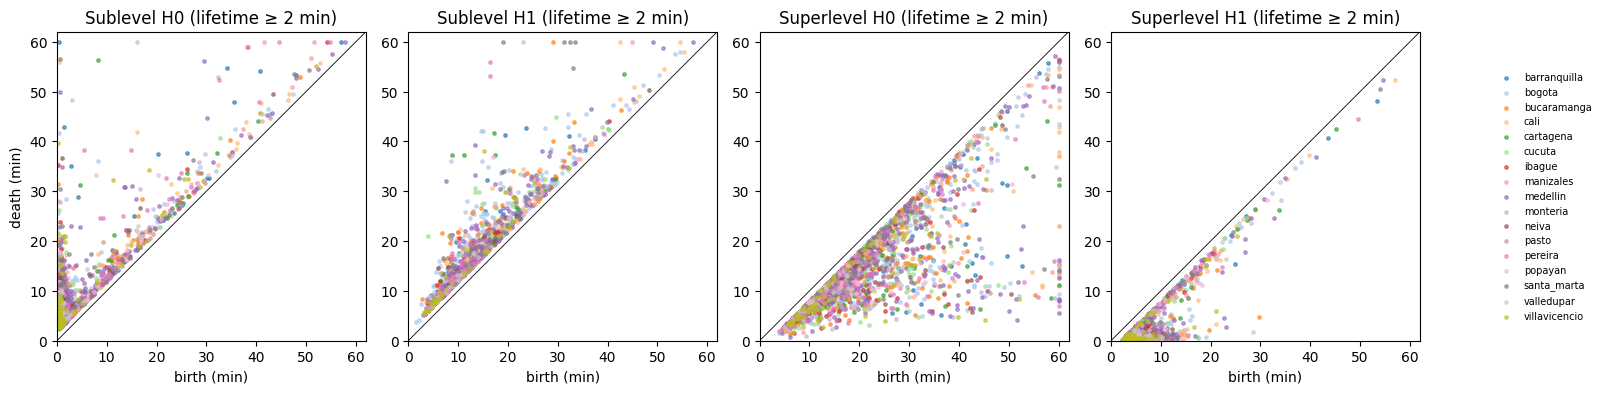

In [18]:
# Filtered diagrams, all cities overlaid (birth vs death, minutes)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
cmap = plt.get_cmap("tab20")
for ax, (key, (_, _, label)) in zip(axes, DIAGRAMS.items()):
    for i, c in enumerate(cities):
        d = PD[(c, key)]; d = d[np.isfinite(d).all(1)]
        ax.scatter(d[:, 0], d[:, 1], s=6, alpha=0.6, color=cmap(i % 20), label=c if key == "sub_h0" else None)
    lim = [0, 62]
    ax.plot(lim, lim, color="k", lw=0.6)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_title(f"{label} (lifetime ≥ {TAU:g} min)"); ax.set_xlabel("birth (min)")
axes[0].set_ylabel("death (min)")
fig.legend(loc="center right", fontsize=7, frameon=False)
fig.tight_layout(rect=(0, 0, 0.9, 1)); fig.savefig(OUT_DIR / f"filtered_diagrams_tau{TAU:g}.png", dpi=200)

## 3. Distances between cities

Two different notions of distance are available. They answer different questions.

### A. Count-normalized optimal transport (`normalized_ot`, default)

Each retained point is changed from birth/death to birth/lifetime coordinates,

$$x_i=(b_i,\ell_i)=(b_i,|d_i-b_i|).$$

It receives either lifetime weight

$$w_i=\frac{\ell_i}{\sum_k\ell_k}$$

or uniform weight $w_i=1/m$. In either case $\sum_iw_i=1$, so city $A$ becomes the
probability measure $\mu_A=\sum_iw_i\delta_{x_i}$. POT's `ot.emd2` solves

$$
d_{\mathrm{OT}}(A,B)=
\min_{\gamma\ge0}\sum_{i,j}\gamma_{ij}\lVert x_i-y_j\rVert_2,
\qquad
\gamma\mathbf 1=w^A,\quad \gamma^\top\mathbf 1=w^B.
$$

`ot.dist(..., metric="euclidean")` supplies the ground-cost matrix
$C_{ij}=\lVert x_i-y_j\rVert_2$; `emd2` returns the minimum objective value (despite
the `2` in its function name, the cost is not squared here). There is no diagonal
matching, and total mass is one for every city. This intentionally compares the
*distribution* of features instead of their count.

### B. Classical persistence-diagram $W_1$ (`classical_w1`)

GUDHI computes the standard diagram distance

$$
W_1(D_A,D_B)=\inf_{\eta}\sum_{p\in D_A}\lVert p-\eta(p)\rVert_2,
$$

where the matching $\eta$ may pair a point with a point in the other diagram or with
the diagonal $\Delta=\{(t,t)\}$. The Euclidean cost of deleting
$p=(b,d)$ via the diagonal is $|d-b|/\sqrt2$. Because unmatched features contribute
cost, this option is sensitive to feature count. Sorting each row puts both sublevel
and reversed superlevel intervals into the conventional `(low, high)` orientation.

### Four matrices and their combination

For every diagram type $r$, the symmetric matrix is
$M^{(r)}_{ij}=d(D_i^{(r)},D_j^{(r)})$, with zeros on the diagonal. Let
$m_r=\operatorname{median}_{i<j}M^{(r)}_{ij}$. The combined matrix is

$$M^{(*)}_{ij}=\frac14\sum_{r=1}^4\frac{M^{(r)}_{ij}}{m_r}.$$

Median scaling prevents a naturally larger-distance diagram type from dominating the
average. It also makes the combined values dimensionless. The final displayed table
computes Spearman correlations between upper triangles, measuring agreement in the
**rank ordering** of city pairs rather than agreement in absolute distance.

In [19]:
def as_measure(d):
    """Finite points as (birth, lifetime) with unit total mass."""
    d = d[np.isfinite(d).all(1)]
    life = np.abs(d[:, 1] - d[:, 0])
    # Change coordinates from (birth, death) to (birth, lifetime).
    X = np.column_stack([d[:, 0], life])
    # Normalize weights to total mass 1, removing dependence on raw point count.
    w = life / life.sum() if WEIGHT == "lifetime" else np.full(len(life), 1 / len(life))
    return X, w

def normalized_ot(da, db):
    """Exact W1 transport between unit-mass empirical measures; no diagonal."""
    Xa, wa = as_measure(da); Xb, wb = as_measure(db)
    # C[i,j] is Euclidean (not squared) cost; emd2 returns min sum(gamma * C).
    return ot.emd2(wa, wb, ot.dist(Xa, Xb, metric="euclidean"))

def classical_w1(da, db):
    """Standard diagram W1 with Euclidean point cost and diagonal matching."""
    from gudhi.wasserstein import wasserstein_distance
    fa = np.sort(da[np.isfinite(da).all(1)], axis=1)   # (low, high) so death >= birth for both filtrations
    fb = np.sort(db[np.isfinite(db).all(1)], axis=1)
    return wasserstein_distance(fa, fb, order=1, internal_p=2)

dist_fn = {"normalized_ot": normalized_ot, "classical_w1": classical_w1}[DISTANCE]

n = len(cities)
DM = {}
for key in DIAGRAMS:
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            M[i, j] = M[j, i] = dist_fn(PD[(cities[i], key)], PD[(cities[j], key)])
    DM[key] = M

# Strict upper-triangle indices: each unordered city pair appears exactly once.
iu = np.triu_indices(n, 1)
# Equal-weight consensus after putting the four distance scales on equal footing.
DM["combined"] = sum(DM[k] / np.median(DM[k][iu]) for k in DIAGRAMS) / len(DIAGRAMS)
TITLES = {k: v[2] for k, v in DIAGRAMS.items()} | {"combined": "Combined (4 diagrams)"}

for key, M in DM.items():
    pd.DataFrame(M, index=cities, columns=cities).to_csv(OUT_DIR / f"dist_{DISTANCE}_{key}_tau{TAU:g}.csv")

# agreement between diagram types (Spearman on upper triangles)
pd.DataFrame({a: {b: pd.Series(DM[a][iu]).corr(pd.Series(DM[b][iu]), method="spearman") for b in DM} for a in DM}).round(2)

,sub_h0,sub_h1,sup_h0,sup_h1,combined
sub_h0,1.00,0.49,0.61,0.63,0.82
sub_h1,0.49,1.00,0.56,0.55,0.77
sup_h0,0.61,0.56,1.00,0.70,0.84
sup_h1,0.63,0.55,0.70,1.00,0.87
combined,0.82,0.77,0.84,0.87,1.00


## 4. Hierarchical clustering and validation

`squareform` converts the upper triangle of each $n\times n$ distance matrix to the
$n(n-1)/2$ condensed vector expected by SciPy. Agglomerative clustering starts with
one cluster per city and repeatedly merges two clusters. With the default average
linkage, the inter-cluster distance is

$$d_{\mathrm{avg}}(A,B)=\frac{1}{|A||B|}\sum_{i\in A}\sum_{j\in B}M_{ij}.$$

The alternatives are $d_{\mathrm{single}}(A,B)=\min_{i\in A,j\in B}M_{ij}$ and
$d_{\mathrm{complete}}(A,B)=\max_{i\in A,j\in B}M_{ij}$. Ward linkage is deliberately
not offered because it assumes Euclidean feature vectors, not an arbitrary precomputed
distance matrix.

For city $i$, after cutting a tree into clusters, define

$$
a(i)=\text{mean distance from $i$ to its own cluster},\qquad
b(i)=\min_{C\ne C_i}\text{mean distance from $i$ to cluster $C$},
$$

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},\qquad
S=\frac1n\sum_i s(i).$$

$s(i)$ near 1 is well separated, near 0 is borderline, and negative suggests a closer
neighbouring cluster. This implementation assigns $s(i)=0$ to a singleton. The selected
`best k` maximizes $S$ over `K_RANGE`; it is an exploratory choice, not a significance
test.

Cophenetic correlation is the Pearson correlation between original pairwise distances
$M_{ij}$ and cophenetic distances $h_{ij}$ (the dendrogram height where $i$ and $j$
first join):

$$r_{\mathrm{coph}}=\operatorname{corr}(M_{ij},h_{ij}),\quad i<j.$$

A larger value means the tree more faithfully preserves the supplied distances.

In [20]:
def silhouette(M, labels):
    """Mean silhouette from a precomputed distance matrix M."""
    s = np.zeros(len(labels))
    for i, l in enumerate(labels):
        same = (labels == l); same[i] = False
        if not same.any():
            continue
        # a: cohesion (within cluster); b: nearest-other-cluster separation.
        a = M[i, same].mean()
        b = min(M[i, labels == o].mean() for o in np.unique(labels) if o != l)
        s[i] = (b - a) / max(a, b)
    return s.mean()

Z, rows = {}, []
for key, M in DM.items():
    # SciPy linkage consumes the condensed upper triangle, not the square matrix.
    cond = squareform(M, checks=False)
    Z[key] = linkage(cond, method=LINKAGE)
    # Pearson correlation between original and tree-implied pairwise distances.
    coph = cophenet(Z[key], cond)[0]
    for k in K_RANGE:
        lab = fcluster(Z[key], k, criterion="maxclust")
        rows.append({"diagram": key, "k": k, "silhouette": silhouette(M, lab), "cophenetic_r": coph,
                     **dict(zip(cities, lab))})
clusters = pd.DataFrame(rows)
clusters.to_csv(OUT_DIR / f"clusters_{DISTANCE}_{LINKAGE}_tau{TAU:g}.csv", index=False)
clusters.pivot(index="k", columns="diagram", values="silhouette").round(3)

diagram,combined,sub_h0,sub_h1,sup_h0,sup_h1
k,,,,,
2,0.337,0.420,0.354,0.370,0.328
3,0.269,0.346,0.357,0.286,0.267
4,0.149,0.312,0.291,0.244,0.266
5,0.119,0.202,0.236,0.191,0.193
6,0.118,0.162,0.150,0.202,0.156


### Figure 3 — dendrograms and silhouette curves

SciPy's `dendrogram` draws each linkage matrix `Z`. Horizontal position is merge
distance; each leaf label is a city. The code places the cut halfway between the two
merge heights surrounding the selected number of clusters, so branch colours correspond
to `k_best`. The sixth panel plots mean silhouette against $k$; the horizontal 0.25 and
0.50 lines are informal visual guides, not universal hypothesis-test thresholds.

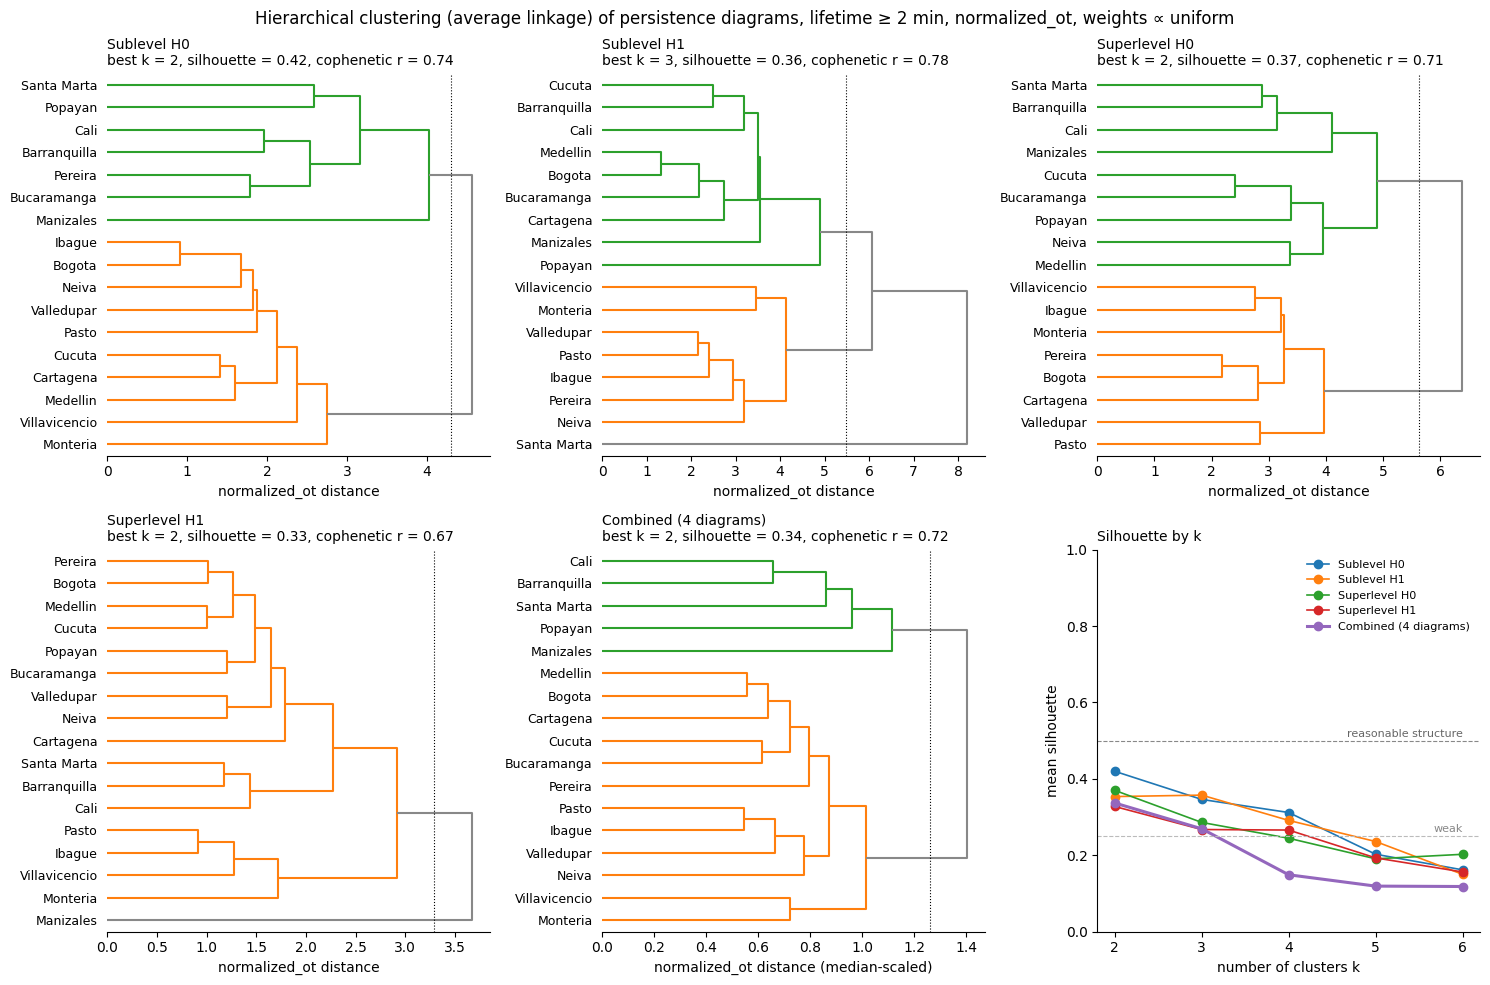

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
order = list(DIAGRAMS) + ["combined"]
for ax, key in zip(axes.flat, order):
    best = clusters[clusters.diagram == key].sort_values("silhouette").iloc[-1]
    k_best = int(best.k)
    # Any cut strictly between these adjacent merge heights yields k_best clusters.
    thr = 0.5 * (Z[key][-(k_best - 1), 2] + Z[key][-k_best, 2])  # cut midway between merges -> k_best clusters
    dendrogram(Z[key], labels=[c.replace("_", " ").title() for c in cities], orientation="right",
               ax=ax, color_threshold=thr, above_threshold_color="#888888", leaf_font_size=9)
    ax.axvline(thr, color="k", ls=":", lw=0.8)
    coph = clusters.loc[clusters.diagram == key, "cophenetic_r"].iloc[0]
    ax.set_title(f"{TITLES[key]}\nbest k = {k_best}, silhouette = {best.silhouette:.2f}, cophenetic r = {coph:.2f}",
                 fontsize=10, loc="left")
    ax.set_xlabel(f"{DISTANCE} distance" + (" (median-scaled)" if key == "combined" else ""))
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)

ax = axes.flat[-1]
for key in order:
    s = clusters[clusters.diagram == key]
    ax.plot(s.k, s.silhouette, marker="o", label=TITLES[key], lw=2.2 if key == "combined" else 1.2)
ax.axhline(0.5, color="#888888", ls="--", lw=0.8); ax.text(K_RANGE[-1], 0.51, "reasonable structure", ha="right", fontsize=8, color="#666")
ax.axhline(0.25, color="#bbbbbb", ls="--", lw=0.8); ax.text(K_RANGE[-1], 0.26, "weak", ha="right", fontsize=8, color="#888")
ax.set_xticks(list(K_RANGE)); ax.set_xlabel("number of clusters k"); ax.set_ylabel("mean silhouette"); ax.set_title("Silhouette by k", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.set_ylim(min(0, clusters.silhouette.min() - 0.05), 1)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

fig.suptitle(f"Hierarchical clustering ({LINKAGE} linkage) of persistence diagrams, lifetime ≥ {TAU:g} min, {DISTANCE}"
             + (f", weights ∝ {WEIGHT}" if DISTANCE == "normalized_ot" else ""), fontsize=12)
fig.tight_layout()
#fig.savefig(OUT_DIR / f"dendrograms_{DISTANCE}_{LINKAGE}_tau{TAU:g}.png", dpi=200, bbox_inches="tight")

### Figure 4 — combined-distance heatmap

`leaves_list` extracts the left-to-right leaf order of the combined dendrogram. The same
permutation $o$ is applied to rows and columns, $M^{(*)}[o,o]$, so visually similar
cities appear next to each other. `imshow` maps small values to dark purple and large
values to yellow under the `viridis` colour map. Reordering changes only presentation,
not any distance or cluster.

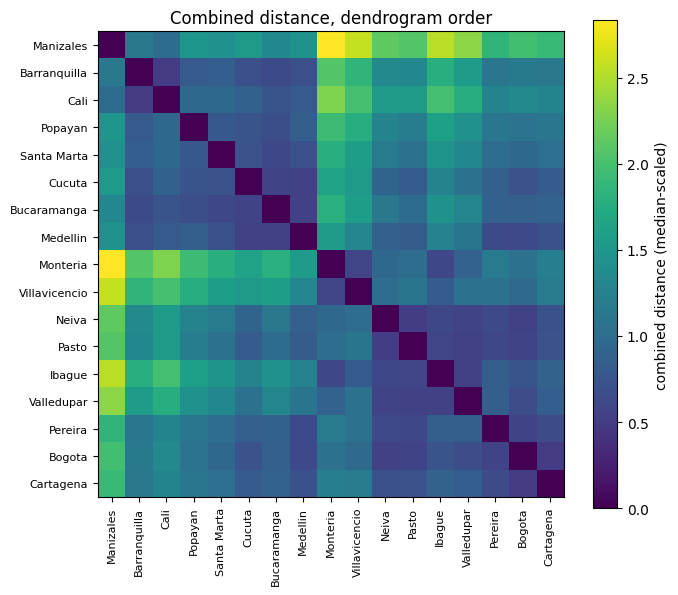

In [24]:
# Combined distance matrix, ordered by the combined dendrogram
# Leaf ordering is cosmetic: use it identically for rows and columns.
o = leaves_list(Z["combined"])
lab = [cities[i].replace("_", " ").title() for i in o]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(DM["combined"][np.ix_(o, o)], cmap="viridis")
ax.set_xticks(range(n), lab, rotation=90, fontsize=8); ax.set_yticks(range(n), lab, fontsize=8)
fig.colorbar(im, ax=ax, label="combined distance (median-scaled)")
ax.set_title("Combined distance, dendrogram order")
fig.tight_layout(); fig.savefig(OUT_DIR / f"combined_distance_heatmap_{DISTANCE}_tau{TAU:g}.png", dpi=200)

### Final table — membership at each diagram's selected $k$

For every diagram type (plus the combined matrix), this cell finds the row with maximum
mean silhouette and places its integer cluster labels beside the cities. Cluster numbers
are arbitrary identifiers: label 1 in one dendrogram has no mathematical correspondence
to label 1 in another. The CSV is useful for comparing membership stability across the
four topological summaries.

In [25]:
# Cluster memberships at each diagram's best k, side by side
best_k = clusters.loc[clusters.groupby("diagram").silhouette.idxmax(), ["diagram", "k"]].set_index("diagram").k
memb = pd.DataFrame({f"{key} (k={best_k[key]})": clusters.query("diagram == @key and k == @best_k[@key]")[cities].iloc[0]
                     for key in order})
memb.to_csv(OUT_DIR / f"best_k_memberships_{DISTANCE}_tau{TAU:g}.csv")
memb

,sub_h0 (k=2),sub_h1 (k=2),sup_h0 (k=2),sup_h1 (k=2),combined (k=2)
barranquilla,1,2,1,1,1
bogota,1,2,2,2,1
bucaramanga,1,2,1,2,1
cali,1,2,1,1,1
cartagena,1,2,2,2,1
cucuta,1,2,1,2,1
ibague,1,1,2,2,1
manizales,2,2,1,1,2
medellin,1,2,1,2,1
monteria,1,1,2,2,1
